# Step 5: final evaluation on MC_Maze

What this notebook does, in order:

1. **Cross-check the metric** against the official `nlb_tools` function.
2. **Re-score the baselines** with the NLB reference settings (50 ms, alpha 0.01).
3. **Train the frozen transformer config with 5 seeds** (about 8 minutes on the GPU).
4. **Compare** with paired bootstrap confidence intervals and the published numbers.
5. **Four figures**: model comparison, per-neuron scores, trial-averaged predictions, single trials.

**Protocol.** The config (dropout 0.5, weight decay 0.1, mask ratio 0.25) was chosen in step 4 by the
internal dev fold. The official validation split is scored once per seed, after training, and nothing is
tuned on it here. Each seed draws its own dev fold, so seed spread includes data-split variation.

In [1]:
%matplotlib inline
import os, io, json, time, contextlib
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from nlb_tools.evaluation import bits_per_spike
from neuralfm.data import load_mc_maze
from neuralfm.baselines import smooth_poisson, mean_rate
from neuralfm.metrics import co_bps, bootstrap_ci, paired_bootstrap_diff
from neuralfm.model import MaskedSpikeTransformer, ModelConfig
from neuralfm.train import parser, run, predict

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10})
C_BASE, C_TF, C_ENS, C_PAPER, C_INK = "#64748b", "#16a34a", "#15803d", "#cbd5e1", "#1f2933"
os.makedirs("../figures", exist_ok=True); os.makedirs("../results/step5", exist_ok=True)

d = load_mc_maze(os.environ.get("NEURALFM_DATA", "../data/000128/sub-Jenkins"),
                 cache="../results/mc_maze_5ms.npz")
N_IN = d["train_in"].shape[2]
print({k: v.shape for k, v in d.items()}, "| GPU:", torch.cuda.get_device_name(0))

{'train_in': (1721, 140, 137), 'train_out': (1721, 140, 45), 'val_in': (573, 140, 137), 'val_out': (573, 140, 45)} | GPU: NVIDIA GeForce RTX 5070 Ti


## 5a. Metric cross-check
The official `bits_per_spike` builds its null model from the **evaluated** spikes' own mean rate. My
training-time metric used the **training** mean. This cell scores the same predictions three ways. The
first two must agree exactly; the third is the stricter variant (the null never sees evaluation data).

In [2]:
glm_old = smooth_poisson(d, sd_ms=40, alpha=0.1)     # settings I used first (copied from explore_data.py)
glm_ref = smooth_poisson(d, sd_ms=50, alpha=0.01)    # NLB reference params for mc_maze
V = d["val_out"]
rows = []
for name, r in [("GLM 40 ms / alpha 0.1", glm_old), ("GLM 50 ms / alpha 0.01", glm_ref)]:
    rows.append({"predictions": name,
                 "official nlb_tools": bits_per_spike(r, V),
                 "mine (eval null)": co_bps(r, V),
                 "mine (train null)": co_bps(r, V, d["train_out"])})
chk = pd.DataFrame(rows).set_index("predictions")
display(chk.round(5))
assert np.allclose(chk["official nlb_tools"], chk["mine (eval null)"], atol=1e-6)
print("OK: my co-bps matches the official function to 1e-6.")

,official nlb_tools,mine (eval null),mine (train null)
predictions,,,
GLM 40 ms / alpha 0.1,0.18825,0.18825,0.18939
GLM 50 ms / alpha 0.01,0.21235,0.21235,0.21350


OK: my co-bps matches the official function to 1e-6.


## 5b. Baselines, scored with the official definition

In [3]:
base = {}
for name, r in [("Mean-rate null", mean_rate(d)), ("GLM 40 ms / 0.1", glm_old),
                ("GLM 50 ms / 0.01 (NLB ref.)", glm_ref)]:
    if name.startswith("Mean-rate"):      # the null is re-estimated inside each resample, so a CI is meaningless
        lo = hi = co_bps(r, V)
    else:
        lo, hi = bootstrap_ci(r, V)
    base[name] = dict(score=co_bps(r, V), lo=lo, hi=hi)
display(pd.DataFrame(base).T.round(4))

,score,lo,hi
Mean-rate null,-0.0011,-0.0011,-0.0011
GLM 40 ms / 0.1,0.1882,0.1811,0.1934
GLM 50 ms / 0.01 (NLB ref.),0.2123,0.2034,0.2189


## 5c. Train the frozen config with 5 seeds
Each run logs to MLflow (`../results/step5/mlflow.db`). Output is suppressed to one line per seed.

In [4]:
SEEDS = [0, 1, 2, 3, 4]
runs, tf_rates = [], []
for seed in SEEDS:
    a = parser().parse_args(["--run-name", "final", "--seed", str(seed), "--epochs", "400",
                             "--patience", "100", "--out", "../results/step5",
                             "--cache", "../results/mc_maze_5ms.npz"])
    a.dropout, a.wd = 0.5, 0.1
    with contextlib.redirect_stdout(io.StringIO()):
        res = run(a)
    ck = torch.load(f"../results/step5/final_s{seed}.pt")
    m = MaskedSpikeTransformer(ModelConfig(**ck["cfg"])).cuda(); m.load_state_dict(ck["state"])
    r = predict(m, d["val_in"], "cuda")[..., N_IN:]
    tf_rates.append(r)
    runs.append(dict(seed=seed, dev_co_bps=res["dev_co_bps"], val_co_bps=co_bps(r, V),
                     train_seconds=res["train_seconds"]))
    print(f"seed {seed}: dev {runs[-1]['dev_co_bps']:.4f}  val {runs[-1]['val_co_bps']:.4f}  "
          f"({runs[-1]['train_seconds']:.0f}s)")
runs = pd.DataFrame(runs).set_index("seed")
ens = np.mean(tf_rates, axis=0)     # average of the 5 models' predicted rates
print(f"\nval co-bps over 5 seeds: {runs.val_co_bps.mean():.4f} +/- {runs.val_co_bps.std(ddof=1):.4f} (SD)")
print(f"5-seed ensemble (average of predicted rates): {co_bps(ens, V):.4f}")

seed 0: dev 0.3264  val 0.3313  (91s)


seed 1: dev 0.3474  val 0.3367  (89s)


seed 2: dev 0.3270  val 0.3403  (91s)


seed 3: dev 0.3400  val 0.3313  (88s)


seed 4: dev 0.3403  val 0.3346  (90s)

val co-bps over 5 seeds: 0.3348 +/- 0.0038 (SD)
5-seed ensemble (average of predicted rates): 0.3522


## 5d. Is the improvement real? Paired bootstrap against the reference baseline
Both models are scored on the *same* resampled trials, so the interval is for the **difference**.

In [5]:
paired = []
for name, r in [(f"seed {s}", tf_rates[i]) for i, s in enumerate(SEEDS)] + [("ensemble", ens)]:
    mean, lo, hi = paired_bootstrap_diff(r, glm_ref, V, n_boot=100)
    paired.append(dict(model=name, diff_vs_GLM_ref=mean, ci_lo=lo, ci_hi=hi))
paired = pd.DataFrame(paired).set_index("model")
display(paired.round(4))
print("Every interval excludes 0:", bool((paired.ci_lo > 0).all()))

,diff_vs_GLM_ref,ci_lo,ci_hi
model,,,
seed 0,0.1185,0.1123,0.1254
seed 1,0.1241,0.1172,0.1314
seed 2,0.1277,0.1210,0.1349
seed 3,0.1188,0.1121,0.1261
seed 4,0.1220,0.1154,0.1293
ensemble,0.1396,0.1336,0.1462


Every interval excludes 0: True


## Figure 1: model comparison and published context
Left: this project (validation split, official metric). Error bars on baselines and the ensemble are 95%
bootstrap CIs over trials; the transformer bar is mean +/- 1 SD over seeds, with individual seeds as dots.
Right: numbers from the NLB'21 paper, Table 1 (MC_Maze). **Caveat:** I have not confirmed which split the
paper's table uses (the official leaderboard scores a hidden test set), so treat the right panel as context,
not a like-for-like comparison.

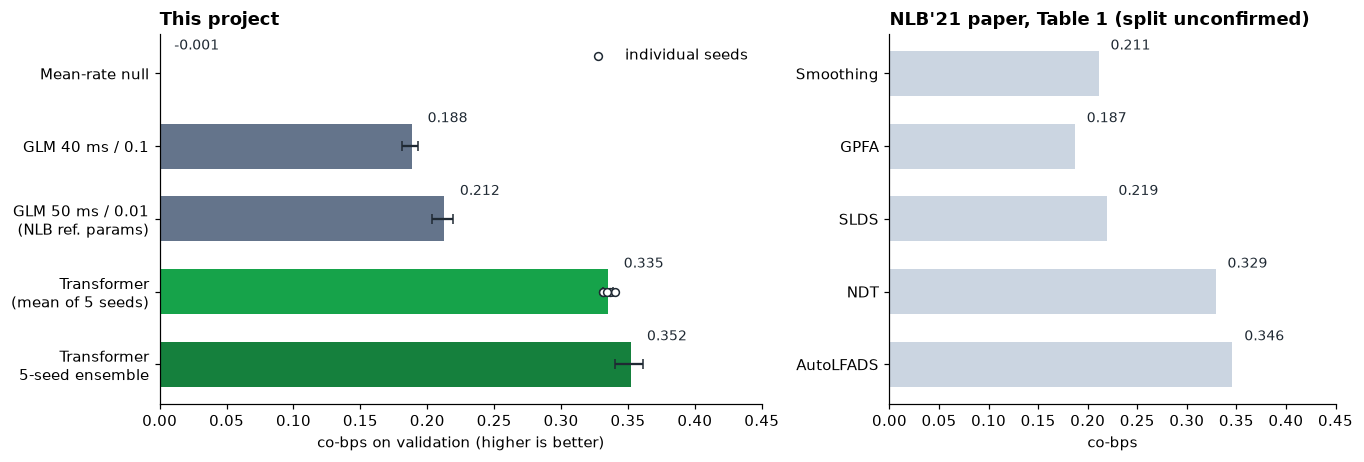

In [6]:
s_tf, sd_tf = runs.val_co_bps.mean(), runs.val_co_bps.std(ddof=1)
s_ens = co_bps(ens, V); lo_e, hi_e = bootstrap_ci(ens, V)
labels = ["Mean-rate null", "GLM 40 ms / 0.1", "GLM 50 ms / 0.01\n(NLB ref. params)",
          "Transformer\n(mean of 5 seeds)", "Transformer\n5-seed ensemble"]
vals = [base["Mean-rate null"]["score"], base["GLM 40 ms / 0.1"]["score"],
        base["GLM 50 ms / 0.01 (NLB ref.)"]["score"], s_tf, s_ens]
xerr = np.array([[0, 0],
                 [vals[1] - base["GLM 40 ms / 0.1"]["lo"], base["GLM 40 ms / 0.1"]["hi"] - vals[1]],
                 [vals[2] - base["GLM 50 ms / 0.01 (NLB ref.)"]["lo"], base["GLM 50 ms / 0.01 (NLB ref.)"]["hi"] - vals[2]],
                 [sd_tf, sd_tf], [s_ens - lo_e, hi_e - s_ens]]).T
cols = [C_BASE, C_BASE, C_BASE, C_TF, C_ENS]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.3), sharex=True,
                             gridspec_kw=dict(width_ratios=[1.35, 1]))
y = np.arange(len(labels))[::-1]
a1.barh(y, vals, xerr=xerr, color=cols, ecolor=C_INK, capsize=3, height=0.62)
a1.scatter(runs.val_co_bps, [y[3]] * len(runs), s=26, c="white", edgecolors=C_INK, zorder=5, label="individual seeds")
for yy, v in zip(y, vals): a1.text(v + 0.012, yy + 0.33, f"{v:.3f}", fontsize=9, color=C_INK)
a1.set_yticks(y); a1.set_yticklabels(labels); a1.set_xlabel("co-bps on validation (higher is better)")
a1.set_title("This project", loc="left", fontweight="bold"); a1.legend(frameon=False, loc="upper right")

paper = {"Smoothing": .211, "GPFA": .187, "SLDS": .219, "NDT": .329, "AutoLFADS": .346}
yp = np.arange(len(paper))[::-1]
a2.barh(yp, list(paper.values()), color=C_PAPER, height=0.62)
for yy, v in zip(yp, paper.values()): a2.text(v + 0.012, yy + 0.33, f"{v:.3f}", fontsize=9, color=C_INK)
a2.set_yticks(yp); a2.set_yticklabels(list(paper)); a2.set_xlabel("co-bps")
a2.set_title("NLB'21 paper, Table 1 (split unconfirmed)", loc="left", fontweight="bold")
a1.set_xlim(0, 0.45); plt.tight_layout()
plt.savefig("../figures/fig1_model_comparison.png", dpi=170, bbox_inches="tight"); plt.show()

## Figure 2: per-neuron scores
Each point is one held-out neuron. Above the diagonal = the transformer beats the reference GLM on that
neuron. Point size shows how many validation spikes the neuron has: **small points are noisy**. Per-neuron
scores run higher than the overall score because the overall co-bps is spike-weighted, so the busy neurons
(large points, mostly lower scores) dominate it.

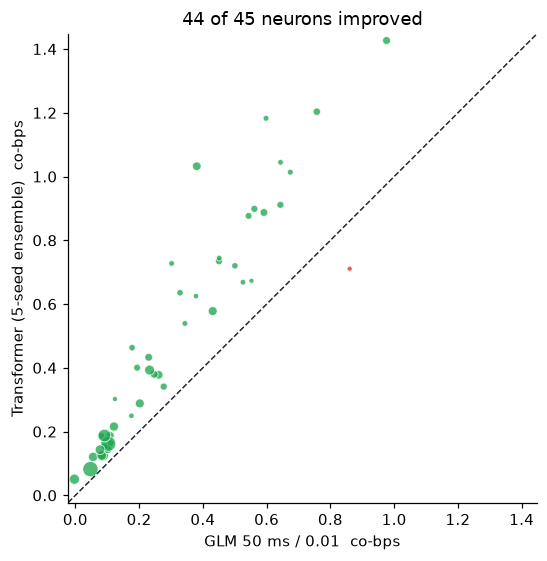

neurons worse than the null (co-bps < 0):  GLM 1 | transformer 0
lowest-spike neurons (unreliable): [56 59 73] spikes


In [7]:
def per_neuron(rates):
    return np.array([co_bps(rates[..., c:c+1], V[..., c:c+1]) for c in range(V.shape[2])])
pn_glm, pn_tf = per_neuron(glm_ref), per_neuron(ens)
n_spk = V.sum((0, 1))
fig, ax = plt.subplots(figsize=(5.6, 5.2))
sc = ax.scatter(pn_glm, pn_tf, s=10 + 90 * n_spk / n_spk.max(), c=np.where(pn_tf > pn_glm, C_TF, "#dc2626"),
                alpha=.75, edgecolor="white", lw=.6)
lim = [min(pn_glm.min(), pn_tf.min()) - .02, max(pn_glm.max(), pn_tf.max()) + .02]
ax.plot(lim, lim, c=C_INK, lw=1, ls="--"); ax.set(xlim=lim, ylim=lim, xlabel="GLM 50 ms / 0.01  co-bps",
    ylabel="Transformer (5-seed ensemble)  co-bps", title=f"{(pn_tf > pn_glm).sum()} of {len(pn_tf)} neurons improved")
ax.set_aspect("equal"); plt.tight_layout()
plt.savefig("../figures/fig2_per_neuron.png", dpi=170, bbox_inches="tight"); plt.show()
print("neurons worse than the null (co-bps < 0):  GLM", int((pn_glm < 0).sum()), "| transformer", int((pn_tf < 0).sum()))
print("lowest-spike neurons (unreliable):", np.sort(n_spk)[:3].astype(int), "spikes")

## Figure 3: trial-averaged predictions
Six held-out neurons, spread across the range of spike counts. Black is the true trial-average on validation
trials; the model never saw these neurons' validation spikes.

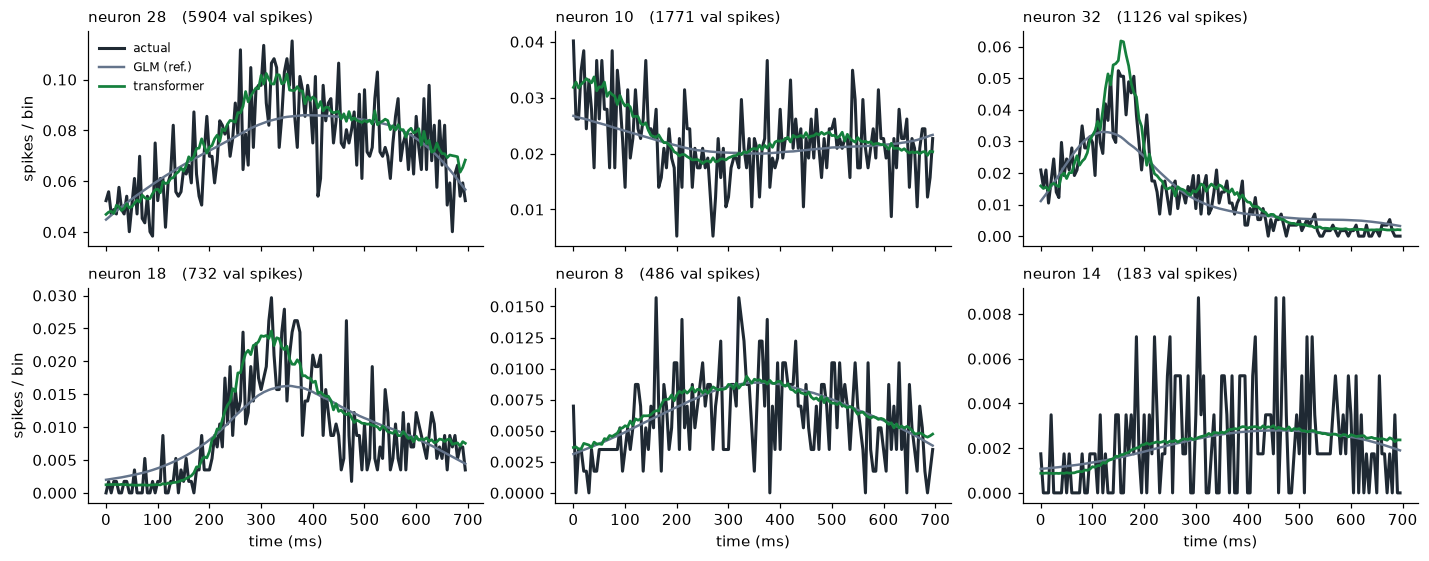

In [8]:
order = np.argsort(n_spk)[::-1]
pick = order[np.linspace(0, 40, 6).astype(int)]
t = np.arange(140) * 5
fig, axes = plt.subplots(2, 3, figsize=(13, 5.2), sharex=True)
for ax, c in zip(axes.flat, pick):
    ax.plot(t, V[:, :, c].mean(0), c=C_INK, lw=2, label="actual")
    ax.plot(t, glm_ref[:, :, c].mean(0), c=C_BASE, lw=1.6, label="GLM (ref.)")
    ax.plot(t, ens[:, :, c].mean(0), c=C_ENS, lw=1.8, label="transformer")
    ax.set_title(f"neuron {c}   ({int(n_spk[c])} val spikes)", fontsize=9.5, loc="left")
axes[0, 0].legend(frameon=False, fontsize=8)
for ax in axes[1]: ax.set_xlabel("time (ms)")
for ax in axes[:, 0]: ax.set_ylabel("spikes / bin")
plt.tight_layout(); plt.savefig("../figures/fig3_trial_averages.png", dpi=170, bbox_inches="tight"); plt.show()

## Figure 4: single trials
Single-trial predictions are the harder test (trial averages hide noise). Ticks along the bottom are the
true spikes of the held-out neuron on that trial; lines are predicted rates. Expect smooth rate modulation, not
individual spikes: spiking is noisy and only the shared signal is predictable.

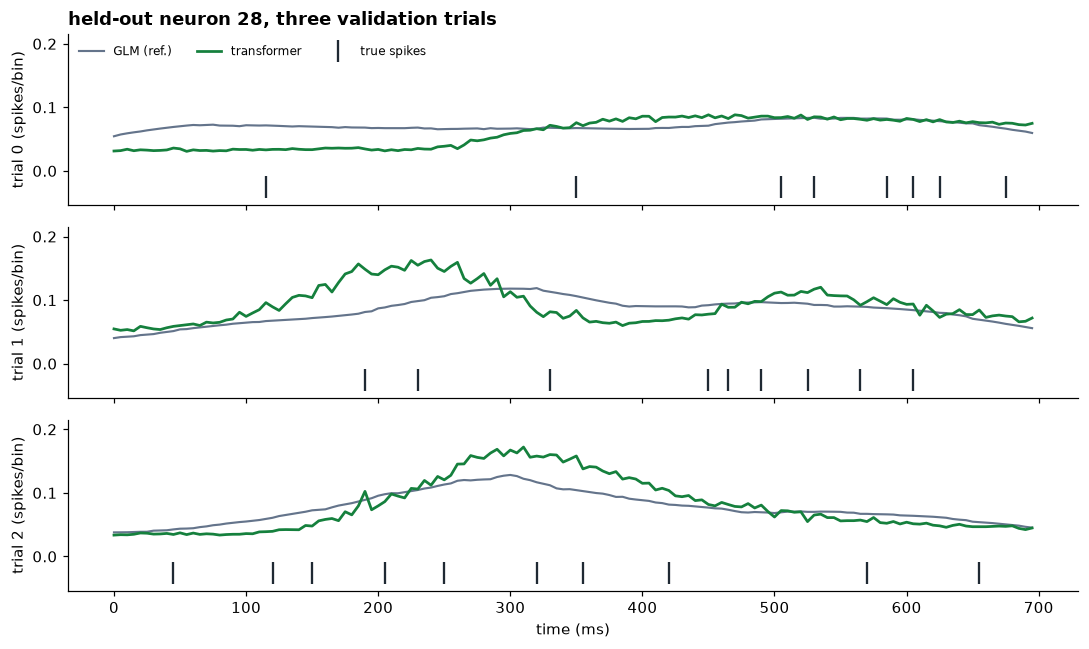

In [9]:
c = order[0]
top = max(glm_ref[:3, :, c].max(), ens[:3, :, c].max()) * 1.25
fig, axes = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
for ax, k in zip(axes, [0, 1, 2]):
    sp = np.nonzero(V[k, :, c])[0]
    ax.plot(t, glm_ref[k, :, c], c=C_BASE, lw=1.4, label="GLM (ref.)")
    ax.plot(t, ens[k, :, c], c=C_ENS, lw=1.8, label="transformer")
    ax.plot(sp * 5, np.full(len(sp), -0.12 * top), "|", c=C_INK, ms=14, mew=1.5, label="true spikes")
    ax.set_ylim(-0.25 * top, top); ax.set_ylabel(f"trial {k} (spikes/bin)")
axes[0].legend(frameon=False, ncol=3, loc="upper left", fontsize=8)
axes[0].set_title(f"held-out neuron {c}, three validation trials", loc="left", fontweight="bold")
axes[-1].set_xlabel("time (ms)"); plt.tight_layout()
plt.savefig("../figures/fig4_single_trials.png", dpi=170, bbox_inches="tight"); plt.show()

## Save results

In [10]:
out = {"protocol": "frozen config chosen on internal dev fold (step 4); official val split scored once per seed",
       "config": {"dropout": 0.5, "weight_decay": 0.1, "mask_ratio": 0.25, "mask_span": 5, "epochs": 400},
       "metric": "co-bps, NLB-official definition (null = mean rate of evaluated spikes)",
       "baselines": base,
       "transformer_seeds": runs.reset_index().to_dict("records"),
       "transformer_mean": float(s_tf), "transformer_sd": float(sd_tf),
       "ensemble": {"score": float(s_ens), "ci95": [lo_e, hi_e]},
       "paired_vs_glm_ref": paired.reset_index().to_dict("records"),
       "published_nlb21_table1": paper,
       "published_caveat": "split used by the paper's table not confirmed; not a like-for-like comparison"}
json.dump(out, open("../results/step5_results.json", "w"), indent=2, default=float)
print("saved ../results/step5_results.json and ../figures/fig1-4")

saved ../results/step5_results.json and ../figures/fig1-4


## Limits to state alongside these results
- **One animal, one session.** Validation trials come from the same session as training, so this measures
  generalisation to new trials, not new days or subjects.
- **Not a leaderboard result.** Scores are on the public validation split with my own implementation; the
  hidden test split and the paper's exact protocol were not used.
- **Hyperparameters were tuned** (step 4) on a dev fold carved from the training trials. The first two sweeps
  also printed validation scores, so selection was not perfectly blind, although the dev fold picked the same
  winner.
- **Ensemble is not a single model.** Report the 5-seed mean as the headline; the ensemble is an extra.
- **Open question:** during training, held-out outputs are computed from inputs with ~22% of bins masked,
  while inference uses full inputs. Whether that mismatch costs accuracy is untested.